###<font color='red'>Made by Anton Rudchenko for ParKinSim (Parallel Kinematic Simulation) project.</font>

#<font color='orange'>This is an overview of different machine learning models' performance for solving inverse kinematic problem of Metrom (Pentapod) machine.

In [ ]:
#@title <font color='yellow'>Imports

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

##<font color='yellow'>Importing and preprocessing data collected from solving direct kinematics in simulation.

In [ ]:
data = pd.read_csv('DKd.csv')

print(data)

         L1    L2    L3    L4    L5        X       Y        Z     RX     RY     RZ
0      14.0  16.0  15.0  15.0  15.0    6.225 -36.857  -29.095  0.255  0.039  0.045
1      13.0  16.0  15.0  15.0  15.0    6.911 -39.529  -26.396  0.274  0.043  0.048
2      12.0  16.0  15.0  15.0  15.0    7.764 -43.206  -23.034  0.301  0.047  0.052
3      11.0  16.0  15.0  15.0  15.0    8.963 -48.874  -18.280  0.342  0.054  0.058
4      11.0  15.0  15.0  15.0  15.0    7.614 -56.939  -13.149  0.400  0.042  0.046
...     ...   ...   ...   ...   ...      ...     ...      ...    ...    ...    ...
10187  87.0  64.0  19.0   8.0  89.0 -104.324  24.796 -110.492 -0.203 -0.400 -0.065
10188  87.0  64.0  19.0   7.0  89.0 -103.399  24.096 -111.093 -0.193 -0.390 -0.058
10189  87.0  64.0  19.0   6.0  89.0 -102.454  23.377 -111.680 -0.184 -0.381 -0.051
10190  87.0  64.0  19.0   5.0  89.0 -101.491  22.639 -112.253 -0.174 -0.372 -0.043
10191  87.0  64.0  19.0   4.0  89.0 -100.508  21.881 -112.813 -0.164 -0.363 -0.034

[10

There are some dublicate data entries from direct kinematics, it is a good practice to get rid of those.

In [ ]:
data = data.drop_duplicates()

print(data)

         L1    L2    L3    L4    L5        X       Y        Z     RX     RY     RZ
0      14.0  16.0  15.0  15.0  15.0    6.225 -36.857  -29.095  0.255  0.039  0.045
1      13.0  16.0  15.0  15.0  15.0    6.911 -39.529  -26.396  0.274  0.043  0.048
2      12.0  16.0  15.0  15.0  15.0    7.764 -43.206  -23.034  0.301  0.047  0.052
3      11.0  16.0  15.0  15.0  15.0    8.963 -48.874  -18.280  0.342  0.054  0.058
4      11.0  15.0  15.0  15.0  15.0    7.614 -56.939  -13.149  0.400  0.042  0.046
...     ...   ...   ...   ...   ...      ...     ...      ...    ...    ...    ...
10187  87.0  64.0  19.0   8.0  89.0 -104.324  24.796 -110.492 -0.203 -0.400 -0.065
10188  87.0  64.0  19.0   7.0  89.0 -103.399  24.096 -111.093 -0.193 -0.390 -0.058
10189  87.0  64.0  19.0   6.0  89.0 -102.454  23.377 -111.680 -0.184 -0.381 -0.051
10190  87.0  64.0  19.0   5.0  89.0 -101.491  22.639 -112.253 -0.174 -0.372 -0.043
10191  87.0  64.0  19.0   4.0  89.0 -100.508  21.881 -112.813 -0.164 -0.363 -0.034

[10

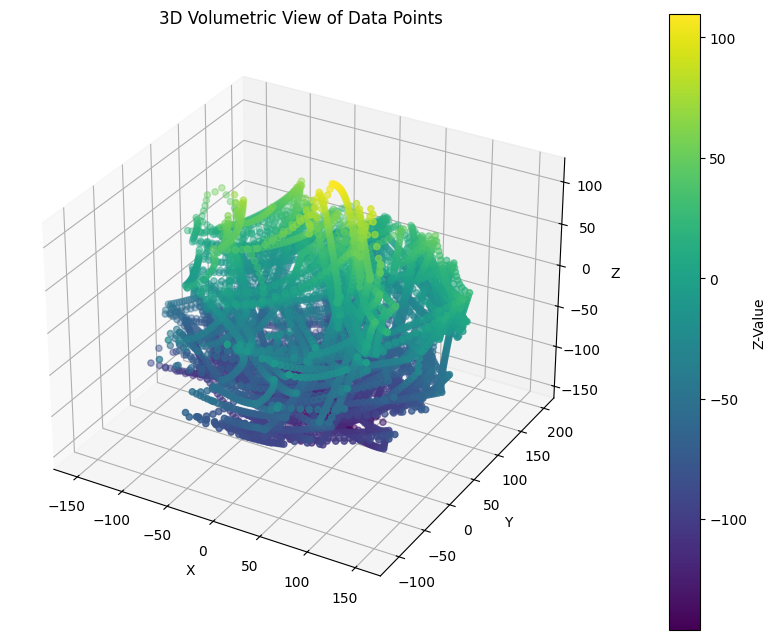

In [ ]:
#@title Plotting XYZ on volumetric plot
x = data['X']
y = data['Y']
z = data['Z']

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(x, y, z, c=z, cmap='viridis', marker='o')

ax.set_title('3D Volumetric View of Data Points')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

color_bar = fig.colorbar(scatter, ax=ax, pad=0.1)
color_bar.set_label('Z-Value')

plt.show()

<font color='red'>REMARK:</font> The dataset was collected again, after some changes were made to the mechanical design of the pentapod.

Further a reverse kinematics problem is going to be solved via ML - Trying to predict LAs based on coords.

##<font color='orange'>Linear Regression model evaluation - <font color='red'>failed</font>

Performance Metrics:
Target L1:
  Mean Squared Error: 52.6285
  R2 Score: 0.9541
Target L2:
  Mean Squared Error: 37.6156
  R2 Score: 0.9556
Target L3:
  Mean Squared Error: 69.8143
  R2 Score: 0.9387
Target L4:
  Mean Squared Error: 41.6137
  R2 Score: 0.9553
Target L5:
  Mean Squared Error: 72.2716
  R2 Score: 0.9329

Model Coefficients:
           X         Y         Z          RX          RY        RZ
L1 -0.020252 -0.520535 -0.737279  -84.395916    2.141053  1.892564
L2 -0.756099 -0.640928 -0.212786 -104.350913  127.436770 -5.821451
L3  0.653014  0.560211 -0.285186   32.962238  -73.463817 -2.738496
L4  0.633032 -0.654398 -0.196647 -108.278567 -109.785898 -2.615585
L5 -0.609037  0.521298 -0.260836   32.373342   62.516081  9.192129

Model Intercepts:
L1    -4.124193
L2     9.484967
L3    13.553870
L4     9.619234
L5    13.644042
dtype: float64


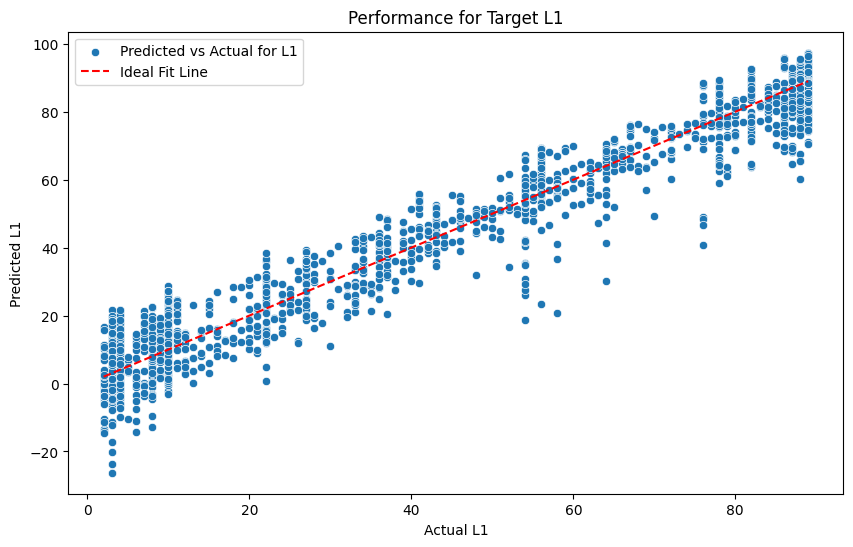

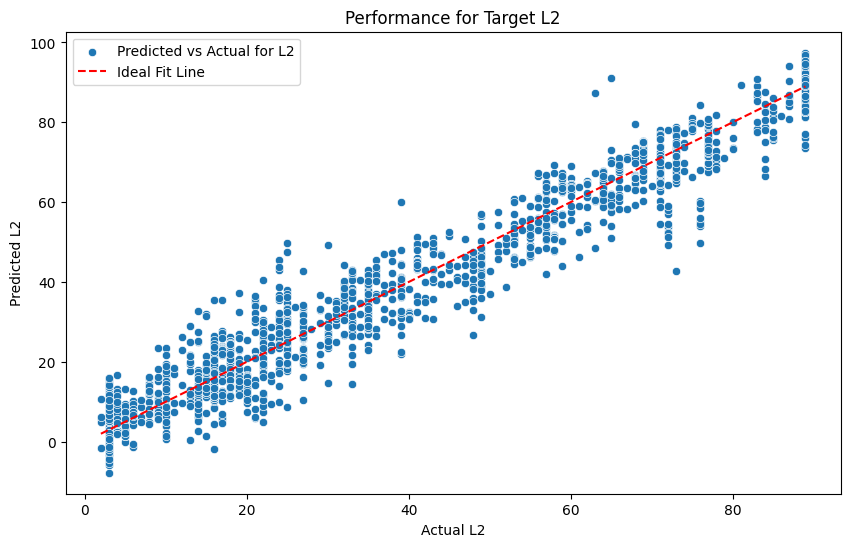

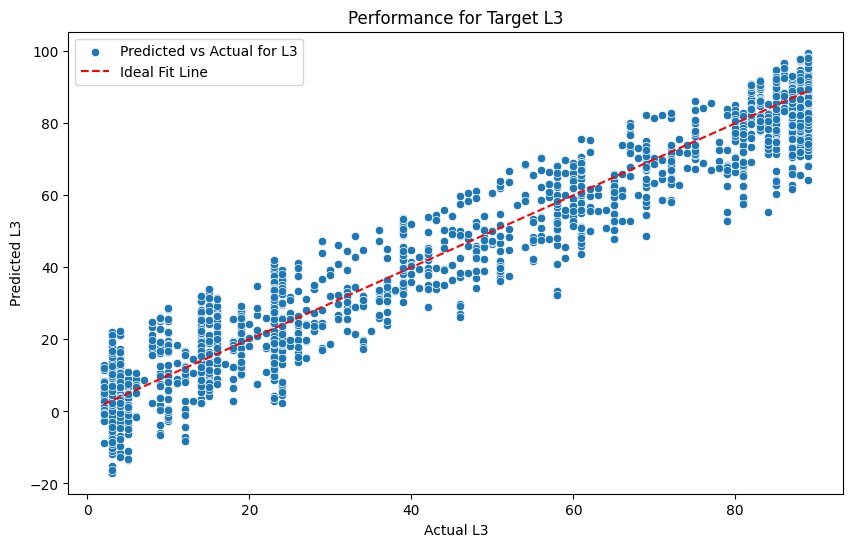

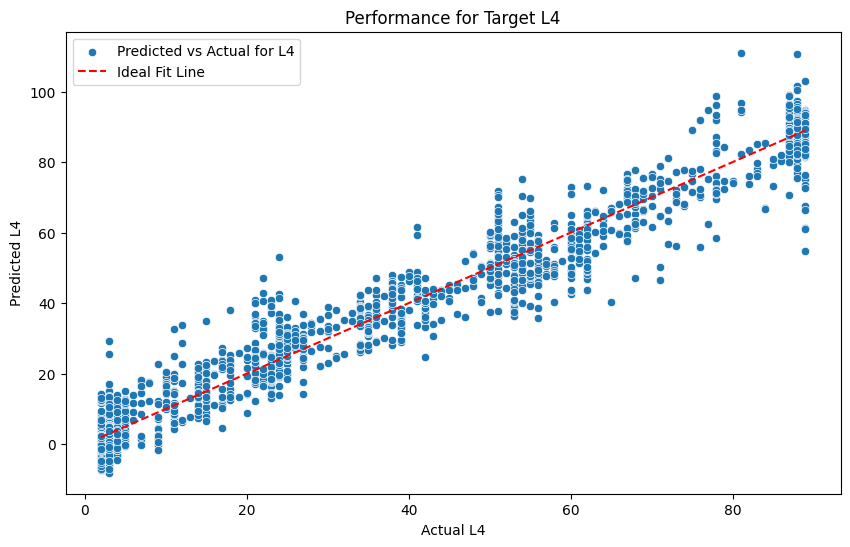

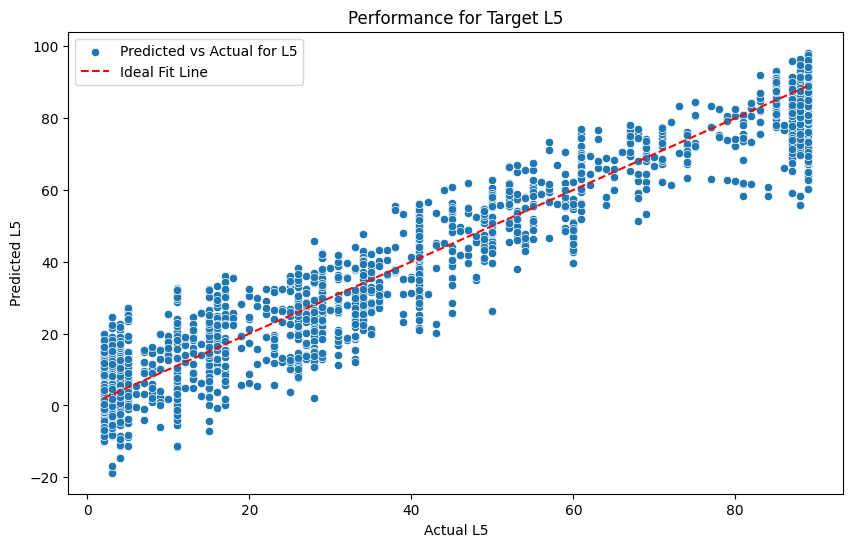

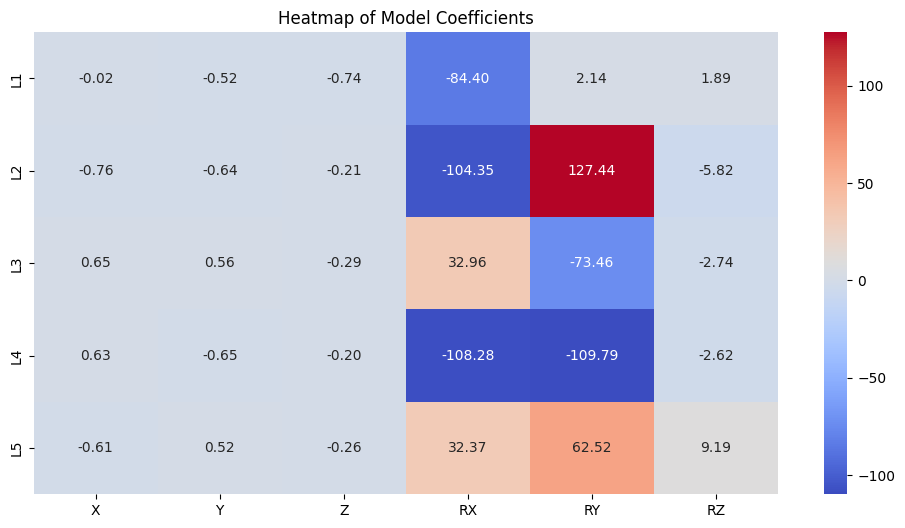

In [ ]:
from sklearn.linear_model import LinearRegression



labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

print("Performance Metrics:")
for i, target in enumerate(labels):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

coefficients = pd.DataFrame(model.coef_, columns=features.columns, index=labels.columns)
intercepts = pd.Series(model.intercept_, index=labels.columns)

print("\nModel Coefficients:")
print(coefficients)
print("\nModel Intercepts:")
print(intercepts)

# Visualization
for i, target in enumerate(labels):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
            [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
            color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(coefficients, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Heatmap of Model Coefficients")
plt.show()


In [ ]:
# Trying to get LAs for X=0, Y=0, Z=0, RX=0, RY=0, RZ=0
# ['3.0', '39.0', '3.0', '24.0', '20.0', '-4.888', '-1.352', '-19.097', '-0.053', '0.036', '0.103'] - one of the entries. an example was predicted for values close to it.

target = [-5, -1, -20, -0.053, 0.036, 0.103]
y_pred = model.predict([target])
np.set_printoptions(precision=4, suppress=True)
print(y_pred)
print("\n")
print(target)
print([-1.483, 2.608, -44.25, -0.028, 0.047, 0.111]) # The simulation check for these values

[[15.9882 27.6808 10.7585 12.5585 22.8662]]


[-5, -1, -20, -0.053, 0.036, 0.103]
[-1.483, 2.608, -44.25, -0.028, 0.047, 0.111]


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


The simulation validation <font color='red'>failed</font>.

##<font color='orange'>ElasticNet Model Evaluation - <font color='red'>failed</font>

Performance Metrics:
Target L1:
  Mean Squared Error: 52.6071
  R2 Score: 0.9541
Target L2:
  Mean Squared Error: 37.5629
  R2 Score: 0.9556
Target L3:
  Mean Squared Error: 69.8464
  R2 Score: 0.9387
Target L4:
  Mean Squared Error: 41.6323
  R2 Score: 0.9552
Target L5:
  Mean Squared Error: 72.2868
  R2 Score: 0.9329

Model Coefficients:
           X         Y         Z          RX          RY        RZ
L1 -0.018425 -0.518796 -0.736542  -84.083588    1.773553  1.883763
L2 -0.750108 -0.639277 -0.212199 -104.066610  126.305528 -5.072738
L3  0.651187  0.558475 -0.285911   32.651032  -73.096531 -2.729830
L4  0.631095 -0.652877 -0.196246 -107.995569 -109.420222 -2.634999
L5 -0.607098  0.519780 -0.261224   32.091466   62.150168  9.211421

Model Intercepts:
L1    -4.022556
L2     9.559692
L3    13.453253
L4     9.697831
L5    13.566465
dtype: float64


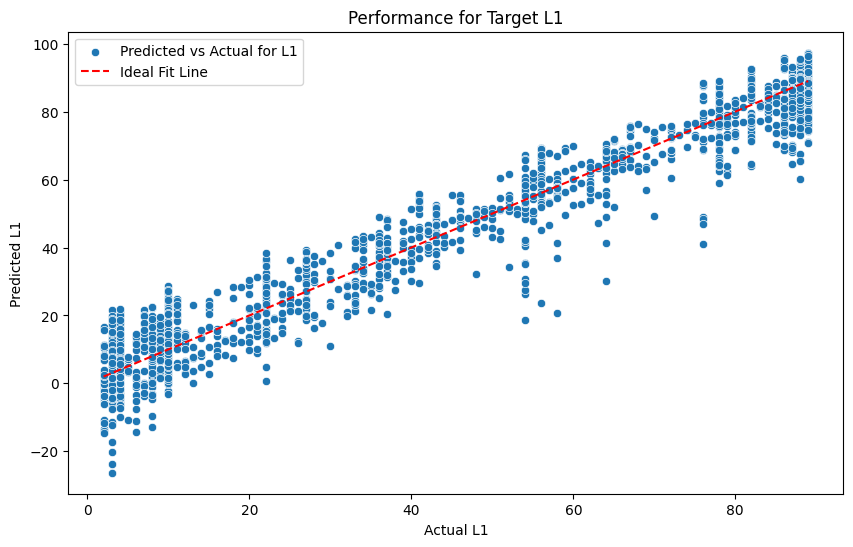

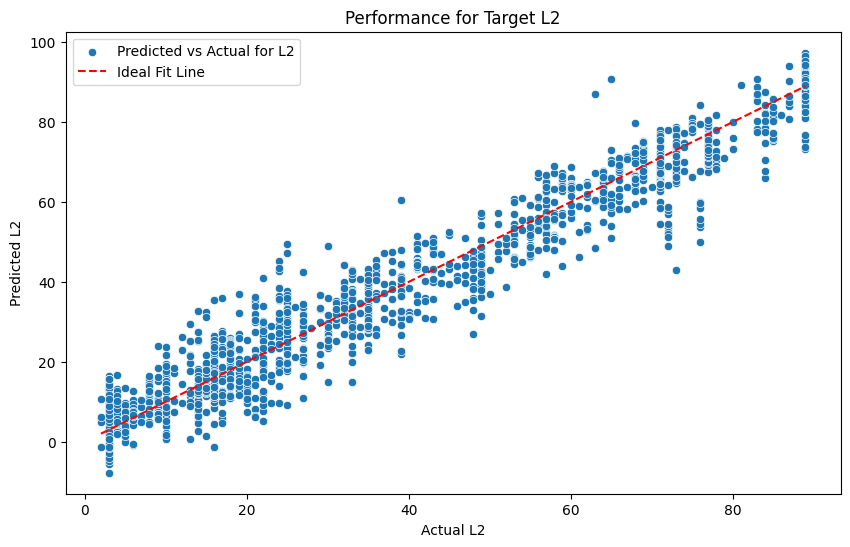

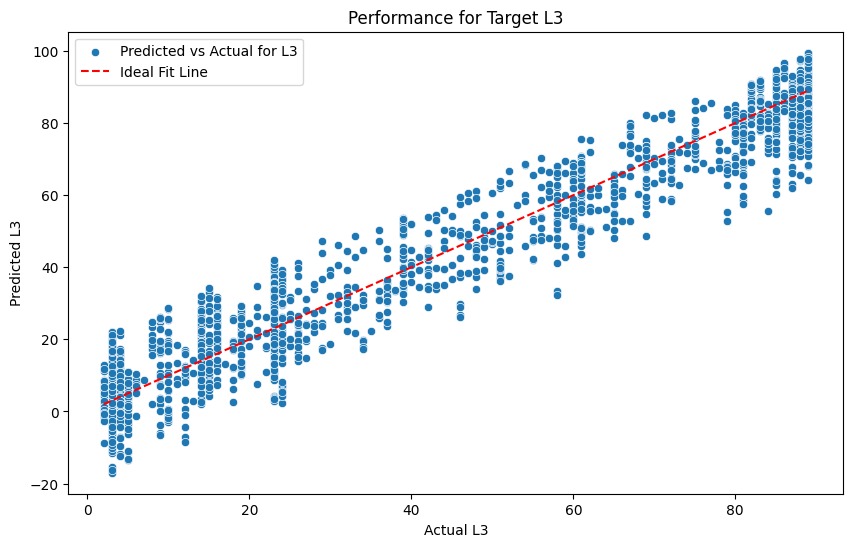

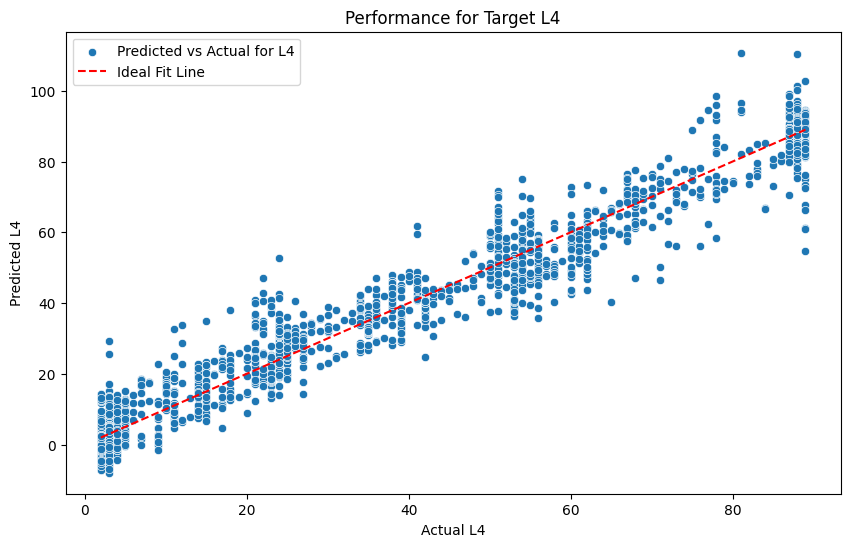

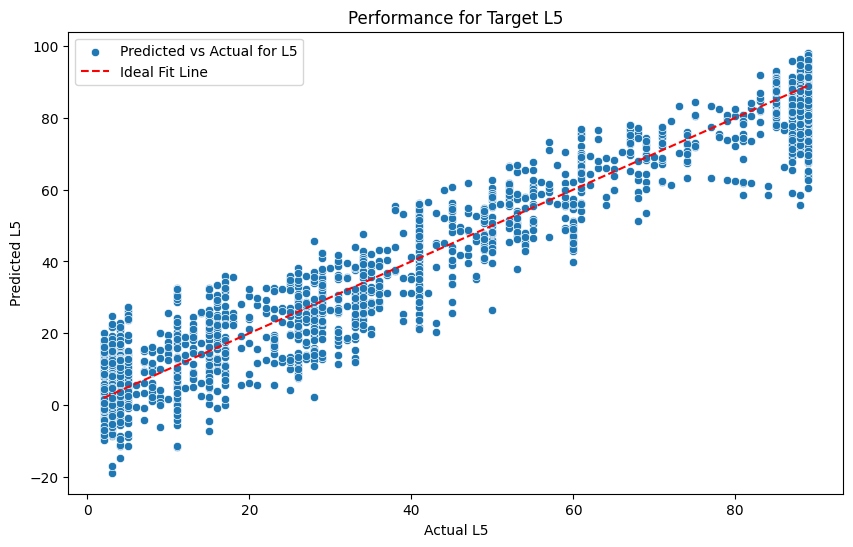

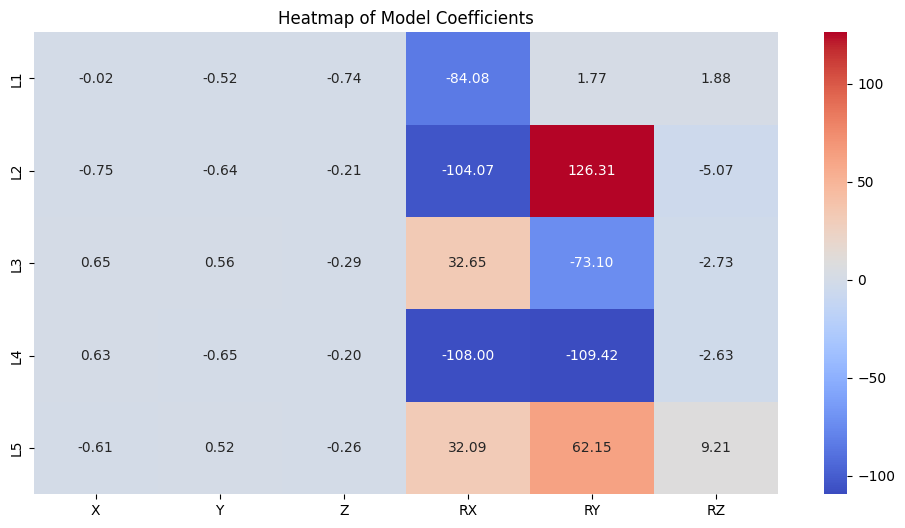

In [ ]:
from sklearn.linear_model import ElasticNet


labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)


# Found via Grid Search
alpha = 0.01  # Regularization strength
l1_ratio = 1.0  # Balance between L1 and L2 regularization

model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

print("Performance Metrics:")
for i, target in enumerate(labels.columns):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

coefficients = pd.DataFrame(model.coef_, columns=features.columns, index=labels.columns)
intercepts = pd.Series(model.intercept_, index=labels.columns)

print("\nModel Coefficients:")
print(coefficients)
print("\nModel Intercepts:")
print(intercepts)

# Visualization
for i, target in enumerate(labels.columns):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(coefficients, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Heatmap of Model Coefficients")
plt.show()

In [ ]:
# Grid Search

from sklearn.model_selection import GridSearchCV

param_grid = {
    'alpha': [0.001, 0.01, 0.1, 1, 10],
    'l1_ratio': [0.1, 0.5, 0.7, 0.9, 1.0]
}
grid_search = GridSearchCV(ElasticNet(), param_grid, cv=5, scoring='neg_mean_squared_error')
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("Best Alpha:", grid_search.best_params_['alpha'])
print("Best L1 Ratio:", grid_search.best_params_['l1_ratio'])

Best Alpha: 0.001
Best L1 Ratio: 1.0


In [ ]:
# Trying to get LAs for X=0, Y=0, Z=0, RX=0, RY=0, RZ=0
# ['3.0', '39.0', '3.0', '24.0', '20.0', '-4.888', '-1.352', '-19.097', '-0.053', '0.036', '0.103'] - one of the entries. an example was predicted for values close to it.

target = [-5, -1, -20, -0.053, 0.036, 0.103]
y_pred = model.predict([target])
np.set_printoptions(precision=4, suppress=True)
print(y_pred)
print("\n")
print(target)
print([-1.43, 2.523, -44.231, -0.028, 0.047, 0.111]) # The simulation check for these values

[[16.0335 27.7335 10.7139 12.6334 22.792 ]]


[-5, -1, -20, -0.053, 0.036, 0.103]
[-1.43, 2.523, -44.231, -0.028, 0.047, 0.111]


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but ElasticNet was fitted with feature names
  warnings.warn(


The simulation validation <font color='red'>failed</font>.

##<font color='orange'>Random Forest Regressor model evaluation - <font color='red'>failed</font>

Performance Metrics:
Target L1:
  Mean Squared Error: 10.3282
  R2 Score: 0.9910
Target L2:
  Mean Squared Error: 12.2598
  R2 Score: 0.9855
Target L3:
  Mean Squared Error: 6.9011
  R2 Score: 0.9939
Target L4:
  Mean Squared Error: 10.2557
  R2 Score: 0.9890
Target L5:
  Mean Squared Error: 6.1314
  R2 Score: 0.9943

Feature Importances:
    Importance
X     0.197425
Y     0.188359
Z     0.279485
RX    0.086302
RY    0.046462
RZ    0.201968


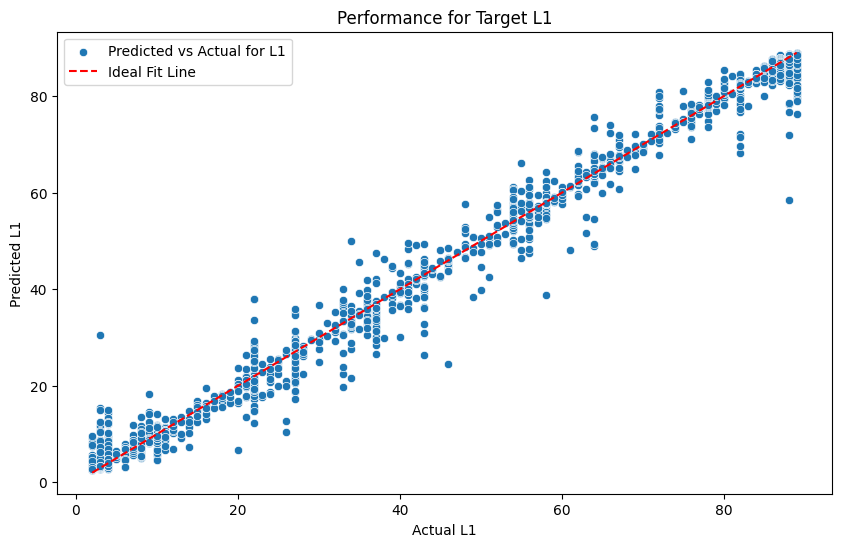

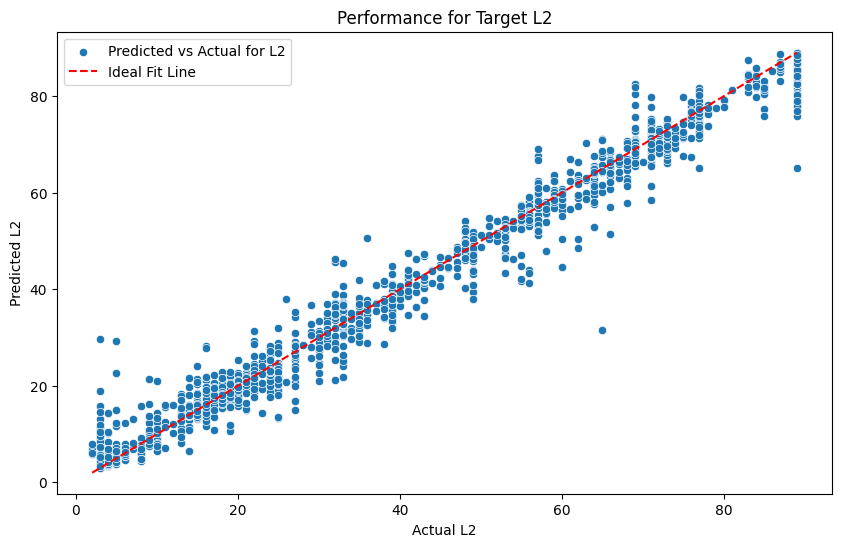

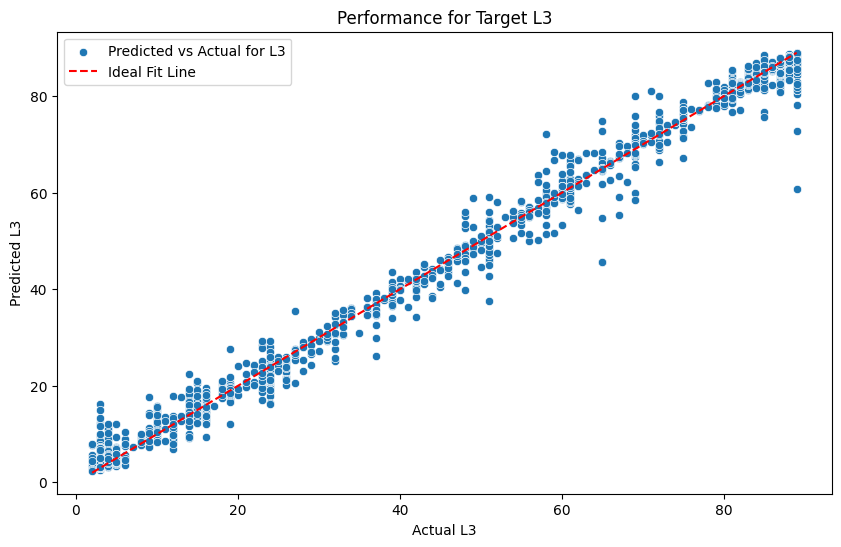

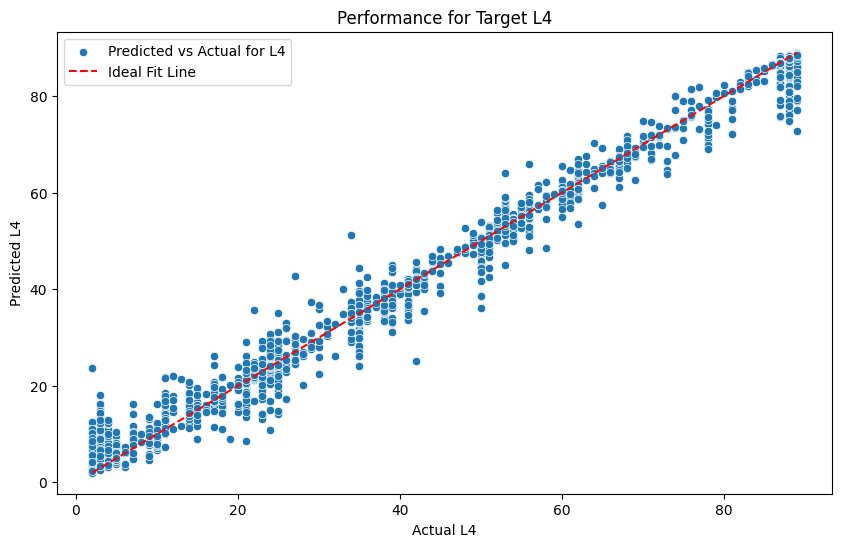

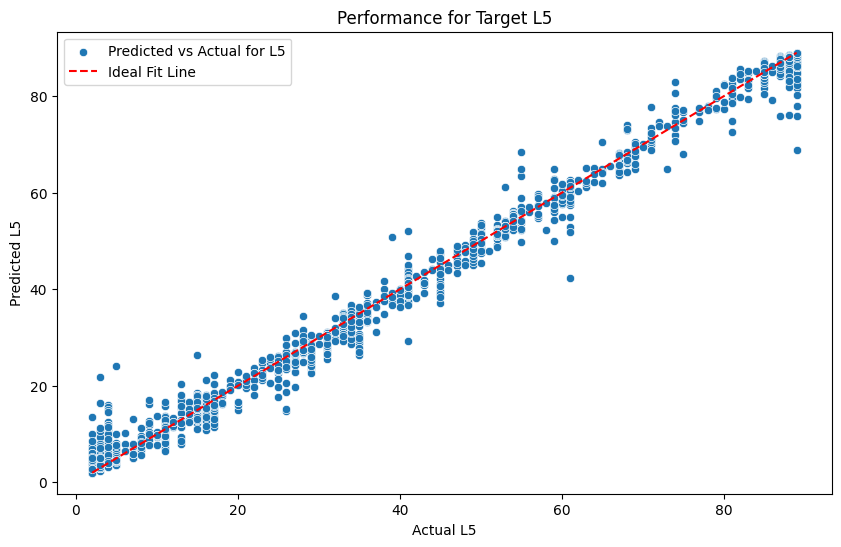

<ipython-input-97-2ee17bc6fd17>:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importances.index, y=feature_importances['Importance'], palette='coolwarm')


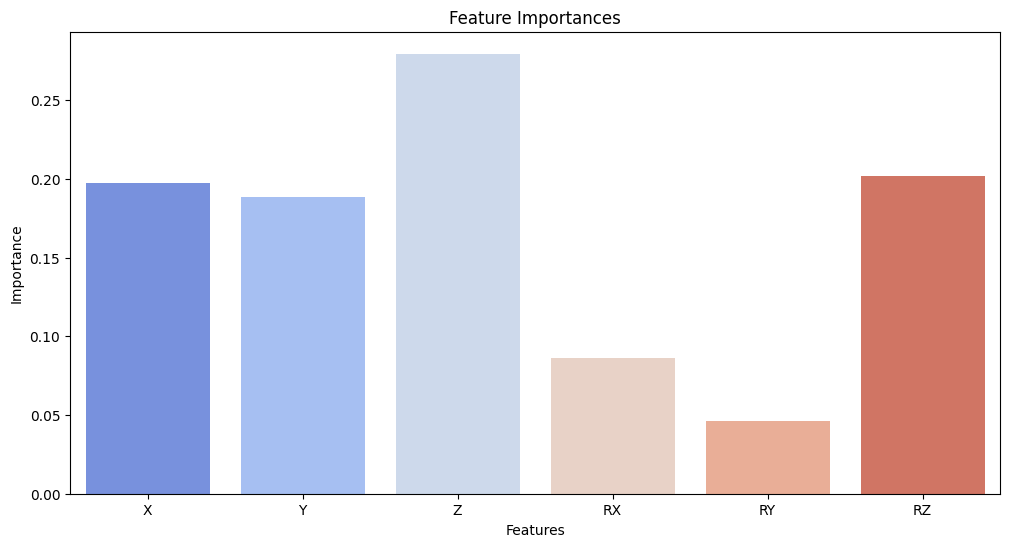

In [ ]:
from sklearn.ensemble import RandomForestRegressor



labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

print("Performance Metrics:")
for i, target in enumerate(labels):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

feature_importances = pd.DataFrame(model.feature_importances_, index=features.columns, columns=['Importance'])

print("\nFeature Importances:")
print(feature_importances)

# Visualization
for i, target in enumerate(labels):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
            [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
            color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(x=feature_importances.index, y=feature_importances['Importance'], palette='coolwarm')
plt.title("Feature Importances")
plt.ylabel("Importance")
plt.xlabel("Features")
plt.show()


In [ ]:
# Trying to get LAs for X=0, Y=0, Z=0, RX=0, RY=0, RZ=0
# ['3.0', '39.0', '3.0', '24.0', '20.0', '-4.888', '-1.352', '-19.097', '-0.053', '0.036', '0.103'] - one of the entries. an example was predicted for values close to it.

target = [-5, -1, -20, -0.053, 0.036, 0.103]
y_pred = model.predict([target])
np.set_printoptions(precision=4, suppress=True)
print(y_pred)
print("\n")
print(target)
print([-6.553, 8.355, -24.27, -0.104, 0.023, 0.096]) # The simulation check for these values

[[ 3.74 36.52  5.01 22.34 21.09]]


[-5, -1, -20, -0.053, 0.036, 0.103]
[-6.553, 8.355, -24.27, -0.104, 0.023, 0.096]


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


The simulation validation <font color='red'>failed</font>.

##<font color='orange'>KNeighborsRegressor model evaluation - <font color='yellow'>close</font>

Performance Metrics:
Target L1:
  Mean Squared Error: 71.8768
  R2 Score: 0.9373
Target L2:
  Mean Squared Error: 136.2350
  R2 Score: 0.8391
Target L3:
  Mean Squared Error: 40.3524
  R2 Score: 0.9646
Target L4:
  Mean Squared Error: 204.5982
  R2 Score: 0.7800
Target L5:
  Mean Squared Error: 44.6934
  R2 Score: 0.9585


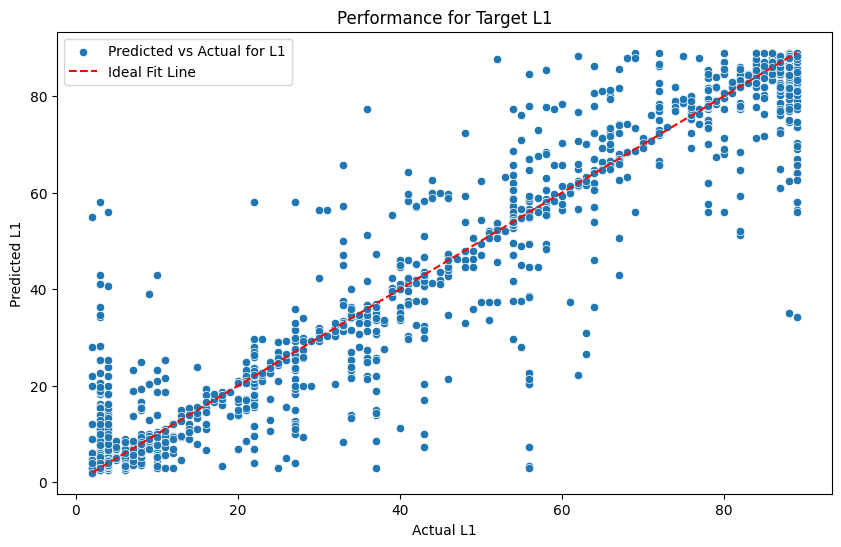

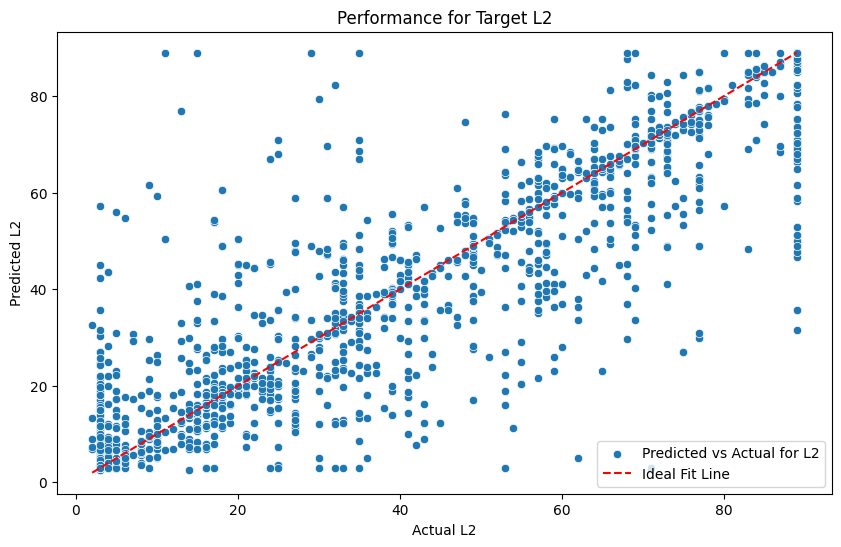

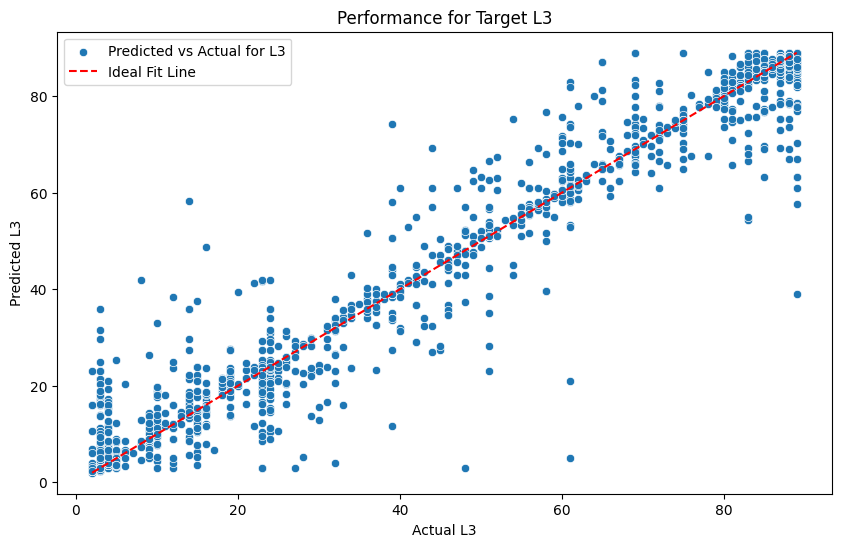

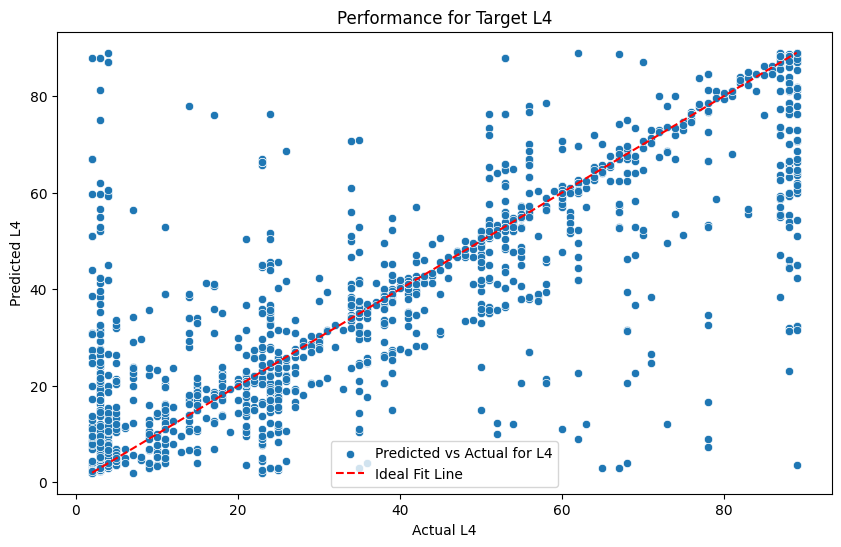

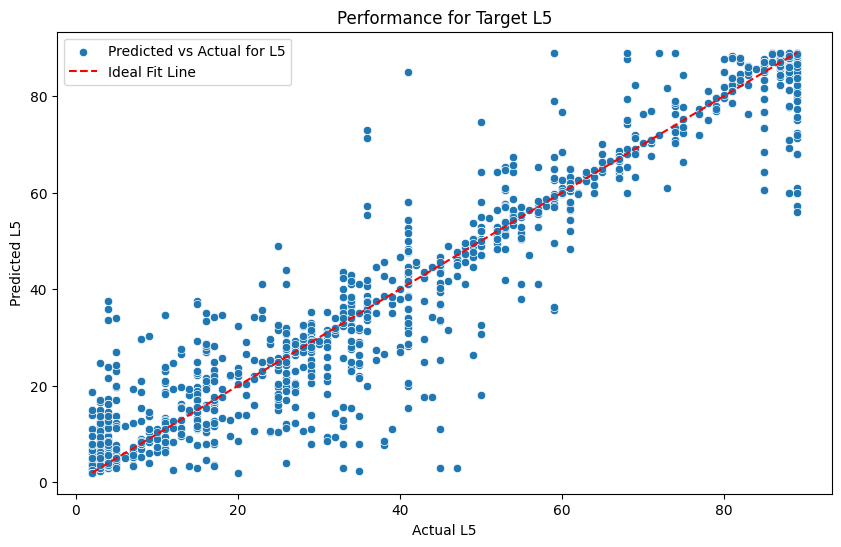

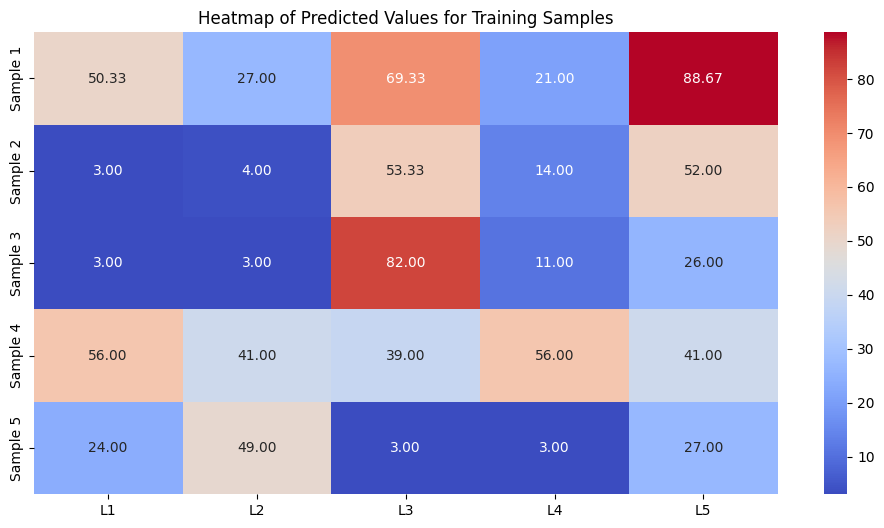

In [ ]:
from sklearn.neighbors import KNeighborsRegressor


labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

n_neighbors = 3  # Number of neighbors to consider
model = KNeighborsRegressor(n_neighbors=n_neighbors)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

print("Performance Metrics:")
for i, target in enumerate(labels.columns):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

# Visualization
for i, target in enumerate(labels.columns):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(pd.DataFrame(model.predict(X_train)[:5], columns=labels.columns, index=[f"Sample {i+1}" for i in range(5)]),
            annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Heatmap of Predicted Values for Training Samples")
plt.show()


In [ ]:
# Trying to get LAs for X=0, Y=0, Z=0, RX=0, RY=0, RZ=0
# ['3.0', '39.0', '3.0', '24.0', '20.0', '-4.888', '-1.352', '-19.097', '-0.053', '0.036', '0.103'] - one of the entries. an example was predicted for values close to it.

target = [-5, -1, -20, -0.053, 0.036, 0.103]
y_pred = model.predict([target])
np.set_printoptions(precision=4, suppress=True)
print(y_pred)

print(target)
print([-5.6, 2.845, -21.319, -0.083, 0.032, 0.101]) # The simulation check for these values

[[ 4. 39.  3. 24. 20.]]
[-5, -1, -20, -0.053, 0.036, 0.103]
[-5.6, 2.845, -21.319, -0.083, 0.032, 0.101]


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(


The simulation validation <font color='orange'>close</font>, consider tuning the parameters.

##<font color='orange'>PolynomialFeatures model evaluation - <font color='green'>quite close</font>

Polynomial regression transforms data into a higher-dimensional space with polynomial features.
Linear Regression then fits a line (hyperplane) in this transformed space.

Performance Metrics:
Target L1:
  Mean Squared Error: 0.0038
  R2 Score: 1.0000
Target L2:
  Mean Squared Error: 0.0039
  R2 Score: 1.0000
Target L3:
  Mean Squared Error: 0.0049
  R2 Score: 1.0000
Target L4:
  Mean Squared Error: 0.0045
  R2 Score: 1.0000
Target L5:
  Mean Squared Error: 0.0093
  R2 Score: 1.0000


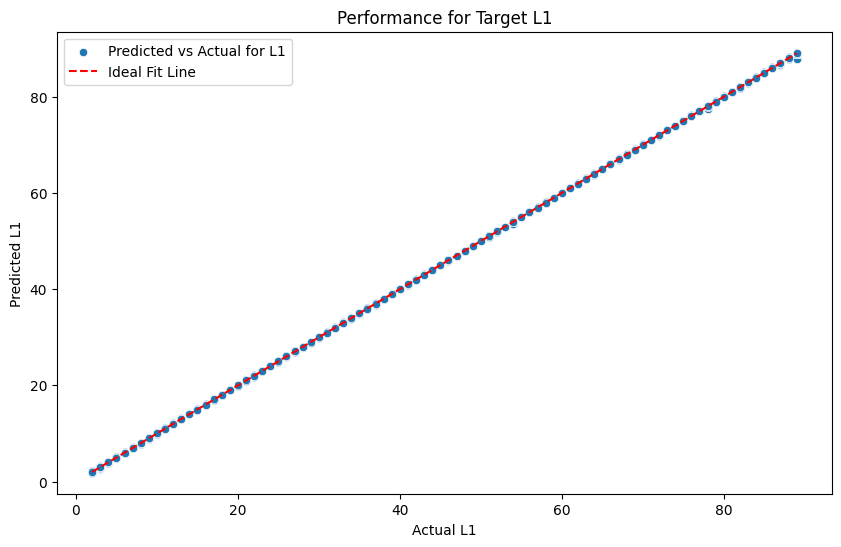

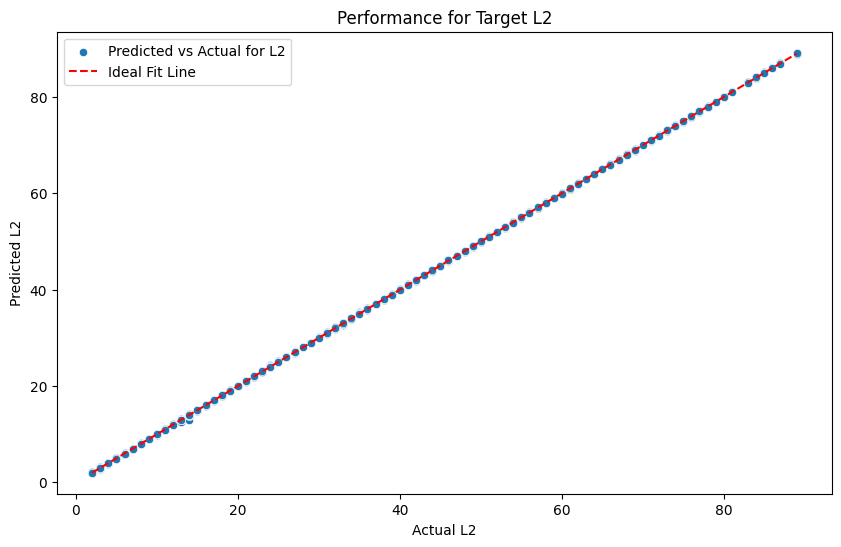

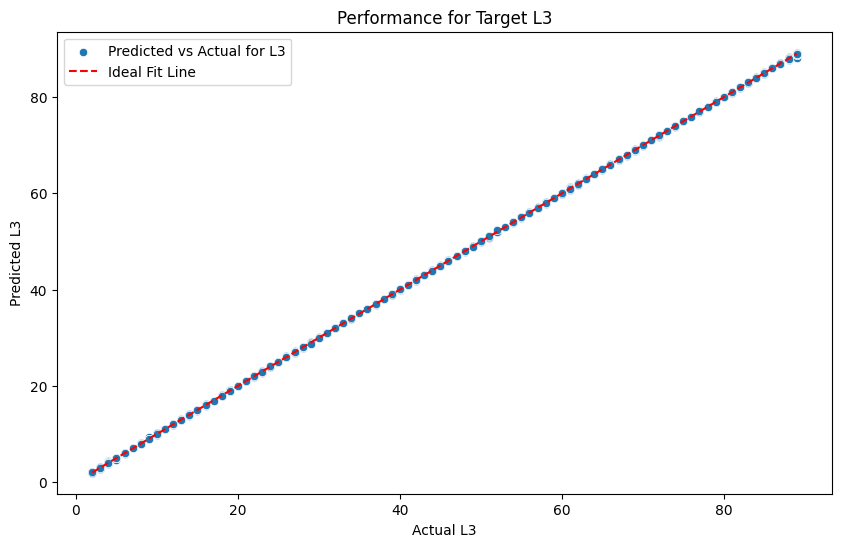

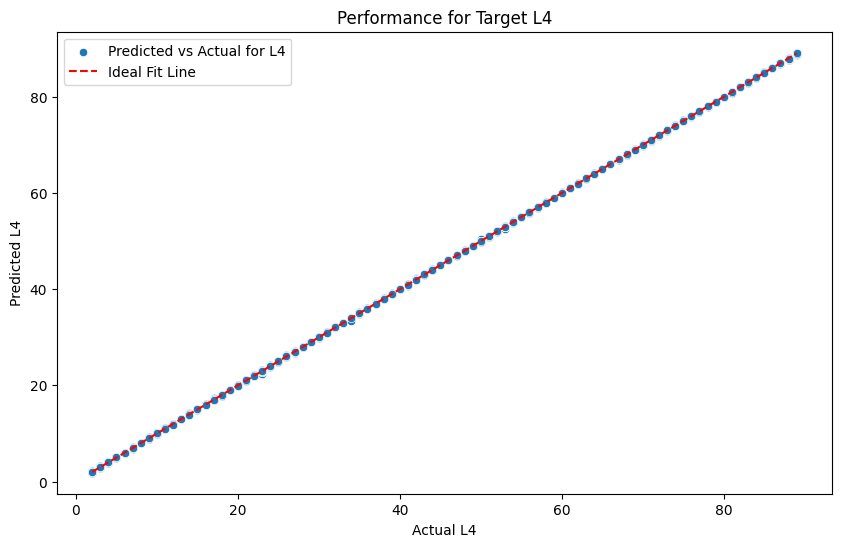

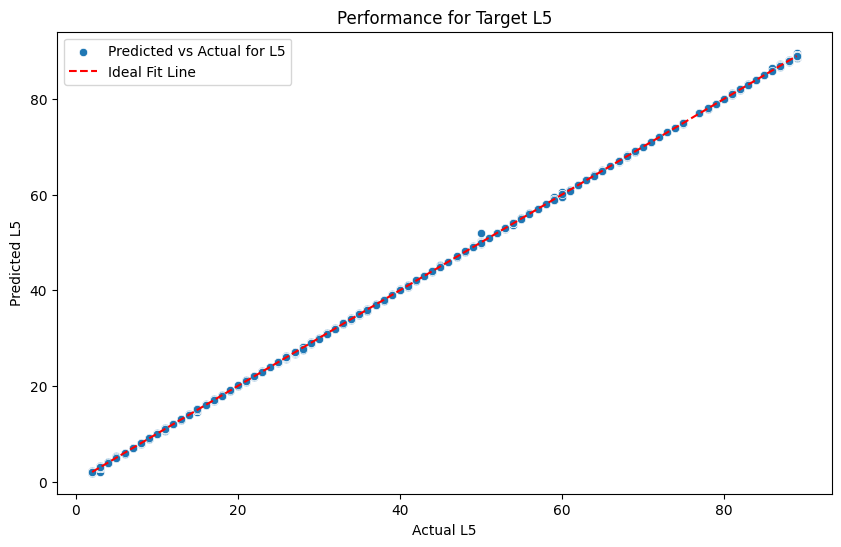

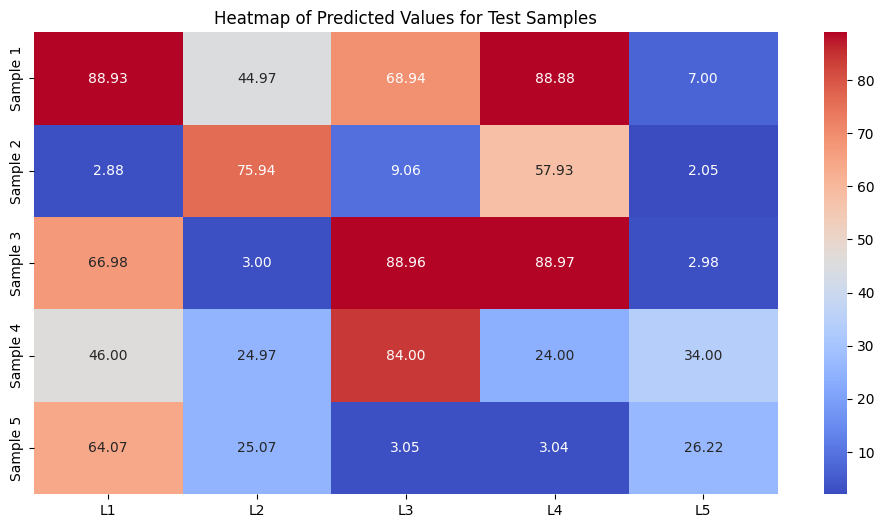

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline


labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

degree = 5

model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

print("Performance Metrics:")
for i, target in enumerate(labels.columns):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

# Visualization
for i, target in enumerate(labels.columns):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(pd.DataFrame(y_pred[:5], columns=labels.columns, index=[f"Sample {i+1}" for i in range(5)]),
            annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Heatmap of Predicted Values for Test Samples")
plt.show()


In [ ]:
# Trying to get LAs for X=0, Y=0, Z=0, RX=0, RY=0, RZ=0
# ['3.0', '39.0', '3.0', '24.0', '20.0', '-4.888', '-1.352', '-19.097', '-0.053', '0.036', '0.103'] - one of the entries. an example was predicted for values close to it.

target = [-5, -1, -20, -0.053, 0.036, 0.103]
y_pred = model.predict([target])
np.set_printoptions(precision=4, suppress=True)
print(y_pred)
print("\n")
print(target)
print([-5.331, -2.635, -19.697, -0.043, 0.033, 0.104]) # The simulation check for these values

[[ 3.5663 38.6736  2.8163 23.5605 20.057 ]]


[-5, -1, -20, -0.053, 0.036, 0.103]
[-5.331, -2.635, -19.697, -0.043, 0.033, 0.104]


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


The simulation validation <font color='orange'>quite close</font>, possibly, data re-engineering is necessary...

##<font color='red'>REMARK:</font> Those are the results based and checked using current dataset, which possibly can be improved.